# Notebook 02 - Pipeline de modelado y evaluación clínica

## Objetivos
- Construir un pipeline reproducible para predecir cáncer de pulmón integrando variables SNOMED, RxNorm y LOINC.
- Preprocesar cada dominio clínico con transformaciones específicas para variables categóricas y numéricas.
- Entrenar y comparar modelos con validación anidada y selección basada en métricas.
- Evaluar desempeño estratificado por edad y género para entender sesgos demográficos.
- Extraer variables importantes y registrar experimentos en MLflow para trazabilidad.
- Guardar preprocesadores y modelos entrenados para reproducibilidad.

## Resumen de secciones y celdas

| Sección | Objetivo | Celdas |
|---|---|---|
| Carga de librerías y datos | Inicializar entorno, cargar datasets y preparar partición train/test | 2-8 |
| Datos SNOMED | Exploración y codificación de diagnósticos/procedimientos | 9-13 |
| Datos de medicamentos (RxNorm) | Exploración y preparación de transformador base | 14-17 |
| Datos de laboratorio (LOINC) | Análisis de tipos, agrupación de categorías y construcción del transformador | 18-30 |
| Análisis de laboratorio | Validación anidada y tuning multmodelo (RF, SVM, XGB, MLP) | 31-38 |
| Evaluación en laboratorio | Curvas ROC-AUC y PR-AUC, reporte de clasificación | 39-40 |
| Pipeline global multimodal | Integración SNOMED + medicamentos + laboratorio con XGBoost | 41-47 |
| Análisis de variables importantes | Extracción top 10 features del modelo XGBoost final | 48 |
| Exploración de importancias | Histogramas de variables por relevancia | 49-55 |
| **Evaluación estratificada** | Métricas desagregadas por grupos de edad y género | 56-60 |
| **Análisis solo laboratorio** | Preprocesamiento y tuning con variables LOINC únicamente | 61-66 |
| Curvas de rendimiento (laboratorio) | ROC-AUC y PR-AUC para modelo de laboratorio | 67 |
| Análisis comparativo avanzado | Comparativa multimodelo con visualizaciones especializadas | 68 |
| Guardado de objetos entrenados | Serialización de preprocesadores y modelos | 69 |
| MLflow: Tracking de experimentos | Inicialización y registro de runs (pendiente) | 70-72 |
| Evaluación comparativa final | Gráficas comparativas entre pipelines (pendiente) | 73+ |

In [2]:
from pathlib import Path
from dotenv import load_dotenv, find_dotenv
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from funciones import obtener_info_valores_unicos, extraccion_columnas


from sklearn.compose import make_column_selector, ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn import set_config
from sklearn.metrics import classification_report, roc_curve, precision_recall_curve, average_precision_score, auc
import numpy as np


from xgboost import XGBClassifier
from interpret.glassbox import ExplainableBoostingClassifier
from interpret import show

import joblib
import os
from glob import glob

import warnings
warnings.filterwarnings('ignore')


## Definición de los datos

In [3]:
load_dotenv(find_dotenv())

PROJECT_ROOT = Path(find_dotenv()).parent.resolve()
print(f"PROJECT_ROOT set to: {PROJECT_ROOT}")
DATA_DIR = PROJECT_ROOT / 'data'

PROJECT_ROOT set to: C:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025


In [4]:
datos_original = pd.read_csv(DATA_DIR / 'synthea_30k.csv', low_memory=False)

In [5]:
datos_SNOMED = pd.read_csv(DATA_DIR / 'synthea_snomed.csv', low_memory=False)
datos_MEDICAMENTOS= pd.read_csv(DATA_DIR / 'synthea_rxnorm.csv',low_memory=False)
datos_LABORATORIO=  pd.read_csv(DATA_DIR / 'synthea_loinc.csv',low_memory=False)

datos_SNOMED.set_index('ptnum', inplace=True)
datos_MEDICAMENTOS.set_index('ptnum', inplace=True)
datos_LABORATORIO.set_index('ptnum', inplace=True)


datos_totales = pd.concat([datos_SNOMED,datos_LABORATORIO, datos_MEDICAMENTOS], axis=1)

In [6]:
X=datos_totales.drop(columns="label")
y=datos_totales["label"]

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.1, random_state=625, stratify=y)

X_train_lab = X_train[datos_LABORATORIO.drop(columns=['label']).columns]
X_test_lab = X_test[datos_LABORATORIO.drop(columns=['label']).columns]

### Datos SNOMED

In [8]:
obtener_info_valores_unicos(datos_SNOMED)

,Indices_iloc,Soporte
0,[218],"[hawaiian, other, asian, black, native, white]"
1,[219],"[s, m]"
2,[220],"[hispanic, nonhispanic]"
3,[221],"[f, m]"
4,[222],[massachusetts]
5,[223],"[50t70, gt70, 30t50]"


In [9]:
col_OH=datos_SNOMED.columns[[218]]
col_OR=datos_SNOMED.columns[[219,220,221,222]]
col_edad=datos_SNOMED.columns[[223]]


#### Procesamiento para diagnosticos y procedimientos

In [10]:
OR_pipeline = Pipeline([
    ("codif", OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])
OH_pipeline = Pipeline([
    ("codif",OneHotEncoder(handle_unknown='ignore',sparse_output=False))])

edad_pipeline = Pipeline([
    ("codif",OrdinalEncoder(categories=[["30t50","50t70","gt70"]],handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))])



preprocesamiento_SNOMED = ColumnTransformer([
    ("OR", OR_pipeline, col_OR),
    ("OH", OH_pipeline, col_OH),
    ("edad", edad_pipeline, col_edad)
], remainder=(SimpleImputer(strategy='constant', fill_value=0.0)), verbose_feature_names_out=False)



### Datos Medicamentos

In [11]:
obtener_info_valores_unicos(datos_MEDICAMENTOS)

""


#### Procesamiento para datos de medicamentos

In [12]:

preprocesamiento_medicamentos = ColumnTransformer([
], remainder=(SimpleImputer(strategy='constant', fill_value=0.0)), verbose_feature_names_out=False)



### Datos de laboratorio

In [13]:
datos_LABORATORIO.drop(columns=["label"],inplace=True)

Ahora que tenemos desglosados los datos, hacer el preprocesamiento es mucho más claro, pues es mucho más simple ver los tipos de las variables, cuantos valores, cómo categorizarlas y como imputar los valores faltantes.

#### Variables numéricas

In [14]:
datos_LABORATORIO.select_dtypes(exclude="object").info()

<class 'pandas.core.frame.DataFrame'>
Index: 4221 entries, p15865 to p9822
Data columns (total 18 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   C reactive protein [Mass/volume] in Serum or Plasma       93 non-null     float64
 1   Red Blood Cell                                            22 non-null     float64
 2   White Blood Cell (Elevated)                               22 non-null     float64
 3   Platelet Count                                            22 non-null     float64
 4   Total Bilirubin (Elevated)                                22 non-null     float64
 5   Fibrin D-dimer FEU [Mass/volume] in Platelet poor plasma  93 non-null     float64
 6   Prothrombin time (PT)                                     93 non-null     float64
 7   Monocytes/100 leukocytes in Blood by Automated count      93 non-null     float64
 8   INR in Platelet p

Como vemos, estas variables numéricas tienen muy pocos datos no nulos, por lo que en este punto tendríamos dos opciones, elimnarlas por completo o discretizarlas, creando una categoría para NAs y otra para cada rango de valores de la variable o directamente estandarizarlas sin tener en cuenta los nulos.

#### Variables categóricas

In [15]:
datos_lab_obj=datos_LABORATORIO.select_dtypes(include="object")


In [16]:
tabla_soportes=obtener_info_valores_unicos(datos_lab_obj)
tabla_soportes

,Indices_iloc,Soporte
0,"[0, 1, 2, 3, 4, 6, 7, 8, 9, 10, 12, 13, 14, 15...","[normal, abnormal]"
1,[5],"[never, former]"
2,"[11, 18, 20, 21, 33, 36, 42]",[normal]
3,[28],"[1+, 3+, 2+]"
4,[30],[2+]
5,[31],[True]
6,[32],"[brown, reddish]"
7,[34],"[negative, positive]"
8,[35],[negative]
9,"[38, 49]",[abnormal]


La mayor parte de las variables de laboratorio toma valores "normal" o "abnormal". Sin embargo, algunas sueltas pueden tomar otros valores. Diferenciaremos estas por grupos de variables para aplicar el *label encoder*

In [17]:
columnas_normal_abnormal = extraccion_columnas(datos_lab_obj,tabla_soportes,[["normal"],["normal","abnormal"],["abnormal","normal"],["abnormal"]])
columnas_former_never = extraccion_columnas(datos_lab_obj,tabla_soportes,[["former","never"],["never","former"]])
columnas_nums= extraccion_columnas(datos_lab_obj,tabla_soportes,[["1+","3+","2+"],["2+", "1+", "3+"],["2+","3+", "1+"],["2+"],["3+","2+", "1+"],["3+","1+", "2+"],["1+","2+", "3+"]])
columnas_brown_reddish = extraccion_columnas(datos_lab_obj,tabla_soportes,[["brown","reddish"],["reddish","brown"]])
columnas_negative_positive= extraccion_columnas(datos_lab_obj,tabla_soportes,[["negative"],["negative","positive"],["positive","negative"],["positive"]])
columnas_false_true= extraccion_columnas(datos_lab_obj,tabla_soportes,[[False,True],[True]])

#### Procesamiento para variables de laboratorio

In [18]:
AN_pipeline = Pipeline([
    ("codif", OrdinalEncoder(categories=[["abnormal", "normal"]]* len(columnas_normal_abnormal),handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])
FT_pipeline = Pipeline([
    ("codif", OrdinalEncoder(categories=[[False,True]] * len(columnas_false_true),handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])
NP_pipeline = Pipeline([
    ("codif", OrdinalEncoder(categories=[["negative","positive"]]* len(columnas_negative_positive),handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])
NUMS_pipeline = Pipeline([
    ("codif", OrdinalEncoder(categories=[["1+","2+","3+"]]* len(columnas_nums),handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])
NF_pipeline = Pipeline([
    ("codif", OrdinalEncoder(categories=[["never","former"]]* len(columnas_former_never),handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])
BR_pipeline = Pipeline([
    ("codif", OrdinalEncoder(categories=[["brown","reddish"]]* len(columnas_brown_reddish),handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])


num_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("imputer", SimpleImputer(strategy='constant', fill_value=0.0))
])

preprocesamiento_lab = ColumnTransformer([
    ("AN", AN_pipeline, columnas_normal_abnormal),
    ("FT", FT_pipeline, columnas_false_true),
    ("NP", NP_pipeline, columnas_negative_positive),
    ("NF", NF_pipeline, columnas_former_never),
    ("NUMS", NUMS_pipeline, columnas_nums),
    ("BR", BR_pipeline, columnas_brown_reddish),

    ("num", num_pipeline,make_column_selector(dtype_exclude="object"))
], remainder="passthrough", verbose_feature_names_out=False)



## Pipeline general

In [19]:
columnas_snomed = datos_SNOMED.columns.tolist()
columnas_medicamentos = datos_MEDICAMENTOS.columns.tolist()
columnas_laboratorio = datos_LABORATORIO.columns.tolist()

In [20]:
preprocesamiento = ColumnTransformer(
    transformers=[
        ("snomed",preprocesamiento_SNOMED,columnas_snomed),
        ("medicamentos",preprocesamiento_medicamentos,columnas_medicamentos),
        ("lab", preprocesamiento_lab, columnas_laboratorio)],
    remainder="passthrough", 
    verbose_feature_names_out=False
)

modelo_xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=25
)
set_config(transform_output="default")

pipeline_final = Pipeline(steps=[
    ('preprocesamiento', preprocesamiento),
    ('modelo_xgb', modelo_xgb)               
])

In [21]:
modelo=pipeline_final.fit(X_train,y_train)

In [22]:
y_pred=modelo.predict(X_test)


In [23]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      1.00       307
           1       0.99      0.98      0.99       116

    accuracy                           0.99       423
   macro avg       0.99      0.99      0.99       423
weighted avg       0.99      0.99      0.99       423



Vemos que a pesar de eliminar ciertas variables del dataset original que pudieran ser reveladoras de cáncer de pulmón y no adecuadas para un cribado general, los resultados siguen siendo inverosímiles.

In [24]:
# Extraer top 10 variables importantes del XGBoost
xgb = modelo.named_steps['modelo_xgb']
feature_names = modelo.named_steps['preprocesamiento'].get_feature_names_out()
importances = xgb.feature_importances_

df_imp = pd.DataFrame({'Variable': feature_names, 'Importancia': importances}).sort_values('Importancia', ascending=False)
variables_importantes = df_imp.head(10)['Variable'].tolist()

print("Top 10 variables importantes:")
print(df_imp.head(10))

Top 10 variables importantes:
                                              Variable  Importancia
181  Cytopathology procedure  preparation of smear ...     0.087694
10                                                 age     0.077788
285                                             Sodium     0.075298
45                     Hypertriglyceridemia (disorder)     0.075080
161                        Urine screening for glucose     0.053669
192                       Echocardiography (procedure)     0.041270
54                                   Anemia (disorder)     0.036627
291  Aspartate aminotransferase [Enzymatic activity...     0.033293
53                                         Prediabetes     0.031464
191                      Plain chest X-ray (procedure)     0.030313


## Análisis exploratorio de variables seleccionadas

### Variable objetivo: Cáncer de pulmón

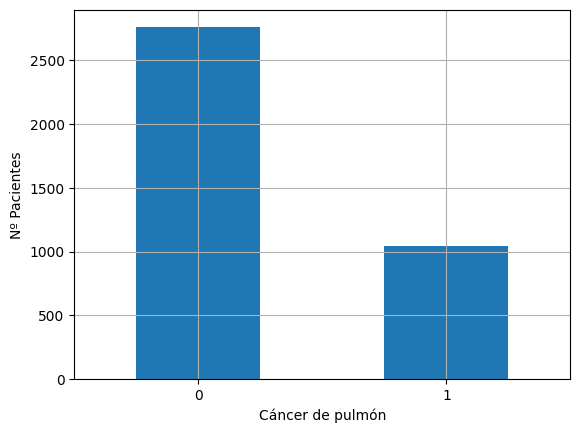

In [25]:
y_train.value_counts().sort_index().plot.bar(rot=0, grid=True)
plt.xlabel("Cáncer de pulmón")
plt.ylabel("Nº Pacientes")
plt.show()

## Distribución general de las variables explicativas

In [26]:
set_config(transform_output="pandas")
X_train_procesado = pipeline_final.named_steps['preprocesamiento'].transform(X_train)
X_test_procesado = pipeline_final.named_steps['preprocesamiento'].transform(X_test)
X_EDA=X_train_procesado[variables_importantes]
X_EDA["cancer_pulmon"]=y_train

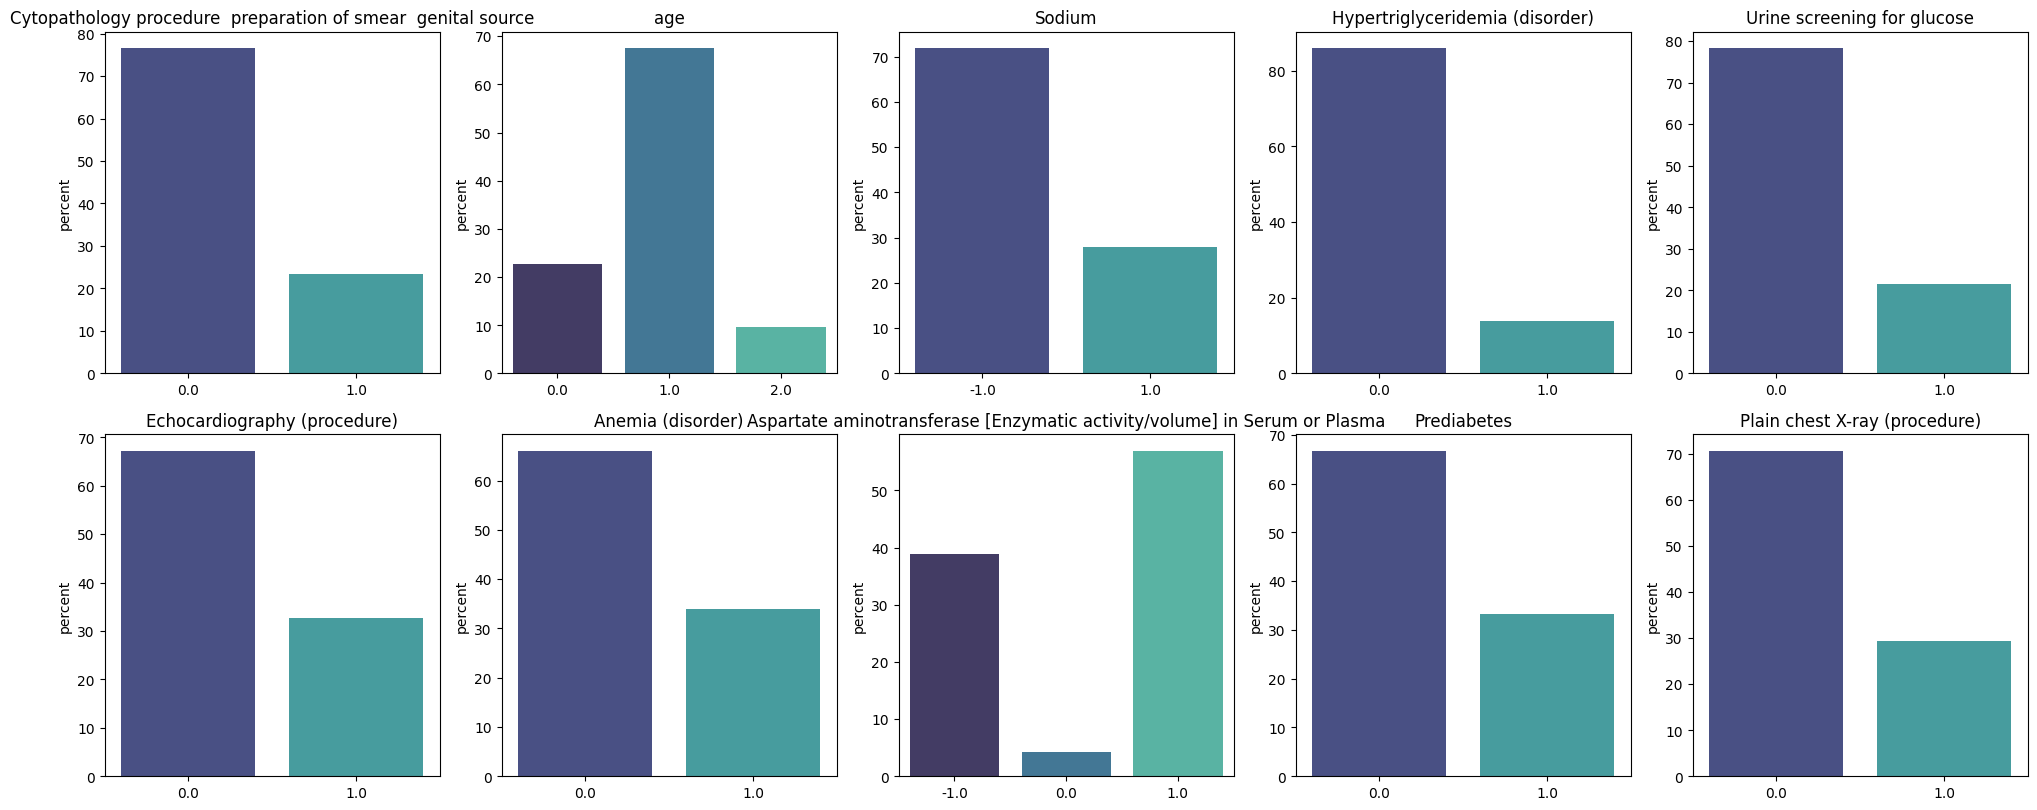

In [27]:
X_EDA_aux=X_EDA.drop(columns="cancer_pulmon")

cols = X_EDA_aux.columns
n_cols = 5
n_rows = (len(cols) // n_cols) + 1

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.countplot(x=X_EDA_aux[col], ax=axes[i], stat="percent", palette="mako")
    axes[i].set_title(col)
    axes[i].set_xlabel("")
    labels = [label.get_text() for label in axes[i].get_xticklabels()]
    # axes[i].set_xticklabels(['Ausente (0)' if label == '0' else 'Presente (1)' for label in labels])

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


Principales hallazgos:
- Principalmente personas de mediana edad (entre 50 y 70 años).
- Más hombres que mujeres en la muestra.
- Sorprendente número de personas con anemia y prediabetes.
- No hay variables numéricas entre las más importantes.

## Influencia de Edad en la cohorte

<Axes: xlabel='age', ylabel='percent'>

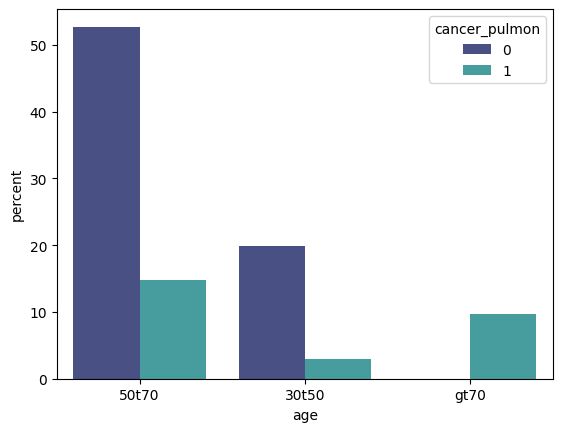

In [28]:
X_EDA["age"] = X_train["age"]
sns.countplot(data=X_EDA,x="age",hue="cancer_pulmon", palette="mako", stat="percent")

Todos las personas mayores de 70 años presentan cáncer. Esto explica la importancia de esta variable para el modelo. En este caso, lo mejor es eliminar los pacientes de este rango de edad.

## Influencia de Género en la cohorte

Text(0.5, 1.0, 'Afectación del cáncer en mujeres y hombres ')

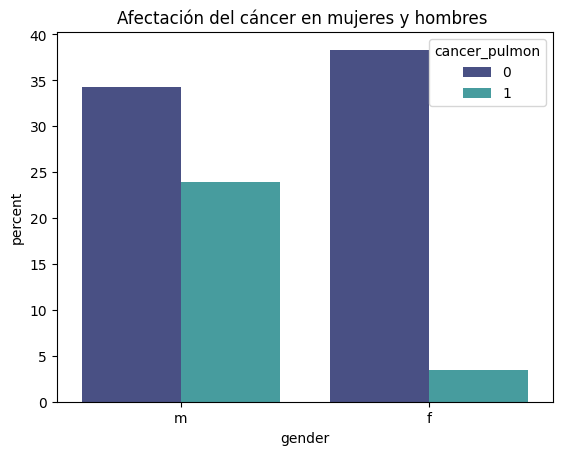

In [29]:
X_EDA["gender"] = X_train["gender"]
sns.countplot(data=X_EDA,x="gender",hue="cancer_pulmon", palette="mako",stat="percent")
plt.title("Afectación del cáncer en mujeres y hombres ")

Muchos más hombres afectados por cáncer que mujeres. 

## Influencia de anemia en la cohorte

<Axes: xlabel='Anemia (disorder)', ylabel='percent'>

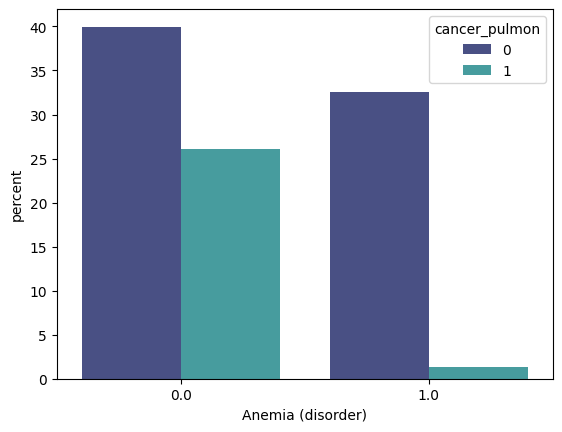

In [30]:
sns.countplot(data=X_EDA,x="Anemia (disorder)",hue="cancer_pulmon", palette="mako", stat="percent")

In [31]:
contingency = pd.crosstab(X_EDA["Anemia (disorder)"], X_EDA["cancer_pulmon"])

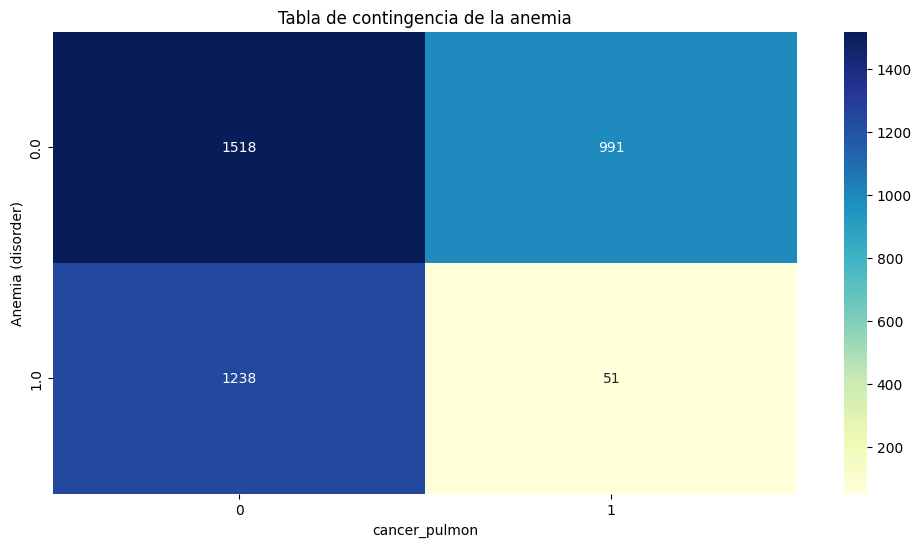

In [32]:
plt.figure(figsize=(12, 6))
sns.heatmap(contingency, annot=True, fmt="", cmap="YlGnBu")
plt.title("Tabla de contingencia de la anemia")
plt.show()
from scipy.stats import fisher_exact

odds_ratio,p_value=fisher_exact(contingency)

In [33]:
print(f"Se obtiene una relacion Odds ratio de {odds_ratio}")



Se obtiene una relacion Odds ratio de 0.06310265735724917


Se rechaza la hipótesis de que la anemia no tenga efecto en el cancer de pulmón. Siendo la anemia un factor protector del cáncer según la estadística.

## Métricas desagregadas por edad

In [34]:
# Evaluar por grupos de edad y género
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

y_pred = modelo.predict(X_test)
y_proba = modelo.predict_proba(X_test)[:, 1] if hasattr(modelo, 'predict_proba') else None

eval_df = X_test[['age', 'gender']].copy().reset_index(drop=True)
eval_df['y_true'] = y_test.reset_index(drop=True)
eval_df['y_pred'] = y_pred

# Convertir age a numérico si es necesario
age_mapping = {'30t50': 40, '50t70': 60, 'gt70': 75}
eval_df['age_num'] = eval_df['age'].map(age_mapping).fillna(eval_df['age']).astype(float)

if y_proba is not None:
    eval_df['y_score'] = y_proba

# Agrupar por edad y género
eval_df['grupo_edad'] = pd.cut(eval_df['age_num'], bins=[0, 49, 59, 69, 120], labels=['<=49', '50-59', '60-69', '>=70'], right=True)

# Calcular métricas por grupo
tabla_desagregada = []
for (edad, genero), group in eval_df.groupby(['grupo_edad', 'gender'], dropna=False):
    tabla_desagregada.append({
        'Edad': edad,
        'Genero': genero,
        'n': len(group),
        'Accuracy': accuracy_score(group['y_true'], group['y_pred']),
        'F1': f1_score(group['y_true'], group['y_pred'], average='weighted', zero_division=0),
        'Recall': recall_score(group['y_true'], group['y_pred'], average='weighted', zero_division=0),
        'Precision': precision_score(group['y_true'], group['y_pred'], average='weighted', zero_division=0),
    })

tabla_desagregada = pd.DataFrame(tabla_desagregada)
print("\n📊 Métricas por Edad y Género:")
print(tabla_desagregada.to_string(index=False))


📊 Métricas por Edad y Género:
 Edad Genero   n  Accuracy       F1   Recall  Precision
 <=49      f  88  1.000000 1.000000 1.000000   1.000000
 <=49      m  21  0.952381 0.952599 0.952381   0.957143
60-69      f  96  1.000000 1.000000 1.000000   1.000000
60-69      m 183  0.989071 0.989026 0.989071   0.989249
 >=70      f   1  1.000000 1.000000 1.000000   1.000000
 >=70      m  34  1.000000 1.000000 1.000000   1.000000


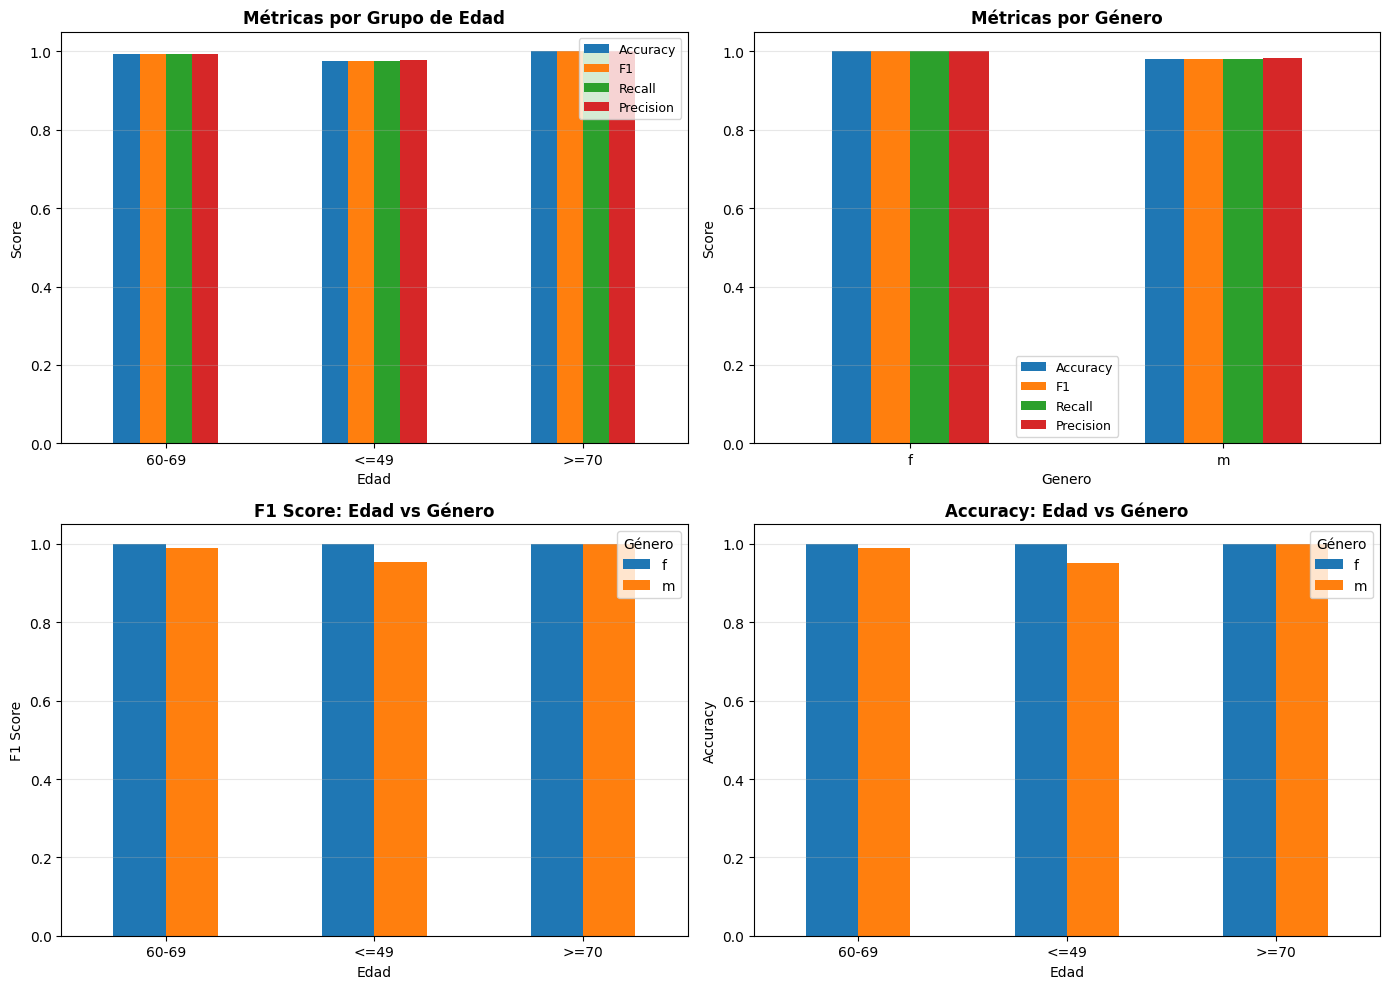

In [35]:
# Gráficas de desagregación
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 10))

# Por edad
tabla_edad = tabla_desagregada.groupby('Edad')[['Accuracy', 'F1', 'Recall', 'Precision']].mean()
tabla_edad.plot(kind='bar', ax=ax1)
ax1.set_title('Métricas por Grupo de Edad', fontweight='bold')
ax1.set_ylabel('Score')
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=0)
ax1.legend(fontsize=9)
ax1.grid(axis='y', alpha=0.3)

# Por género
tabla_genero = tabla_desagregada.groupby('Genero')[['Accuracy', 'F1', 'Recall', 'Precision']].mean()
tabla_genero.plot(kind='bar', ax=ax2)
ax2.set_title('Métricas por Género', fontweight='bold')
ax2.set_ylabel('Score')
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=0)
ax2.legend(fontsize=9)
ax2.grid(axis='y', alpha=0.3)

# F1 Score por edad-género
tabla_pivot = tabla_desagregada.pivot_table(values='F1', index='Edad', columns='Genero')
tabla_pivot.plot(kind='bar', ax=ax3)
ax3.set_title('F1 Score: Edad vs Género', fontweight='bold')
ax3.set_ylabel('F1 Score')
ax3.set_xticklabels(ax3.get_xticklabels(), rotation=0)
ax3.legend(title='Género')
ax3.grid(axis='y', alpha=0.3)

# Accuracy por edad-género
tabla_pivot_acc = tabla_desagregada.pivot_table(values='Accuracy', index='Edad', columns='Genero')
tabla_pivot_acc.plot(kind='bar', ax=ax4)
ax4.set_title('Accuracy: Edad vs Género', fontweight='bold')
ax4.set_ylabel('Accuracy')
ax4.set_xticklabels(ax4.get_xticklabels(), rotation=0)
ax4.legend(title='Género')
ax4.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Modelo solo con analíticas

Debido a los sospechosos resultados cuando contamos con todas las variables disponibles, trataremos de acotar estas variables, usando únicamente las variables de laboratorio para desarrollar un nuevo modelo y analizar resultados.

In [36]:
X_train_lab_procesado = preprocesamiento_lab.fit_transform(X_train_lab)
X_test_lab_procesado = preprocesamiento_lab.transform(X_test_lab)

In [37]:
# 1. Crear el directorio 'models' si no existe
os.makedirs('models', exist_ok=True)

# 2. Guardar el objeto preprocesamiento_lab fitteado
ruta_guardado = 'models/preprocesamiento_lab.joblib'
joblib.dump(preprocesamiento_lab, ruta_guardado)

print(f"Preprocesamiento guardado exitosamente en: {ruta_guardado}")

Preprocesamiento guardado exitosamente en: models/preprocesamiento_lab.joblib


In [37]:
from funciones import tunear_multiples_modelos, resumen_tuning
from glob import glob

print("=" * 80)
print("BÚSQUEDA DE HIPERPARÁMETROS CON CV - DATOS SIN PROCESAR")
print("=" * 80)

directorio_modelos = "models"
os.makedirs(directorio_modelos, exist_ok=True)

# Buscar modelos guardados previamente
modelos_guardados = glob(os.path.join(directorio_modelos, "mejor_modelo_analiticas_*.joblib"))

if modelos_guardados:
    print("\n✅ Modelos guardados encontrados:")
    for modelo_path in modelos_guardados:
        print(f"   - {os.path.basename(modelo_path)}")
    
    # Cargar el primer modelo guardado
    ruta_modelo = modelos_guardados[0]
    mejor_modelo_analiticas = joblib.load(ruta_modelo)
    mejor_modelo_nombre = os.path.basename(ruta_modelo).replace("mejor_modelo_analiticas_", "").replace(".joblib", "")

    print(f"\n✓ Modelo cargado desde: '{ruta_modelo}'")
    print(f"✓ Modelo seleccionado: {mejor_modelo_nombre}")
else:
    print("\n⏳ No hay modelos guardados. Ejecutando búsqueda de hiperparámetros...")
    
    # Tuning con datos CRUDOS + pipeline de preprocesamiento
    resultados_analiticas = tunear_multiples_modelos(
        modelos=['RandomForest', 'SVM', 'XGBoost', 'MLPClassifier'],
        X_train=X_train_lab,  # Datos SIN procesar
        y_train=y_train,
        preprocessing_pipeline=preprocesamiento_lab,  # Pipeline integrada
        cv=5,
        scoring='f1_macro'
    )
    
    # Generar resumen comparativo
    resumen = resumen_tuning(resultados_analiticas)
    
    # Obtener mejor modelo
    if not resumen.empty:
        mejor_modelo_nombre = resumen.iloc[0]['Modelo']
        mejor_modelo_analiticas = resultados_analiticas[mejor_modelo_nombre]['mejor_modelo']
        
        print(f"\n✓ Mejor modelo encontrado: {mejor_modelo_nombre}")
        
        # Definir la ruta del archivo y guardar el modelo
        ruta_modelo = os.path.join(directorio_modelos, f"mejor_modelo_analiticas_{mejor_modelo_nombre.lower()}.joblib")
        joblib.dump(mejor_modelo_analiticas, ruta_modelo)
        
        print(f"✓ Mejor modelo guardado exitosamente en: '{ruta_modelo}'")
    else:
        print("⚠️ No hay resultados válidos")

# Hacer predicciones (la pipeline está integrada)
print("\n" + "=" * 80)
print("EVALUACIÓN EN TEST")
print("=" * 80)

y_pred = mejor_modelo_analiticas.predict(X_test_lab)
y_pred_proba = mejor_modelo_analiticas.predict_proba(X_test_lab)[:, 1]

# Métricas
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, f1_score

print(f"\nF1-Score: {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba):.4f}")

print("\n📊 Matriz de confusión:")
print(confusion_matrix(y_test, y_pred))

print("\n📈 Reporte de clasificación:")
print(classification_report(y_test, y_pred, target_names=['Sin cáncer', 'Con cáncer']))

BÚSQUEDA DE HIPERPARÁMETROS CON CV - DATOS SIN PROCESAR

✅ Modelos guardados encontrados:
   - mejor_modelo_analiticas_mlpclassifier.joblib

✓ Modelo cargado desde: 'models\mejor_modelo_analiticas_mlpclassifier.joblib'
✓ Modelo seleccionado: mlpclassifier

EVALUACIÓN EN TEST

F1-Score: 0.8061
ROC-AUC: 0.9330

📊 Matriz de confusión:
[[285  22]
 [ 40  76]]

📈 Reporte de clasificación:
              precision    recall  f1-score   support

  Sin cáncer       0.88      0.93      0.90       307
  Con cáncer       0.78      0.66      0.71       116

    accuracy                           0.85       423
   macro avg       0.83      0.79      0.81       423
weighted avg       0.85      0.85      0.85       423



### Gráficas AUC


F1-Score: 0.8494
ROC-AUC: 0.9330


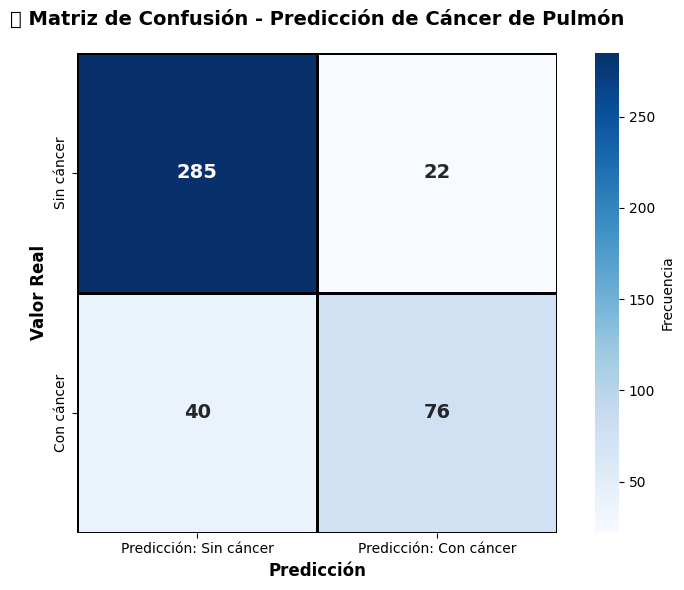


📈 Reporte de clasificación:
              precision    recall  f1-score   support

  Sin cáncer       0.88      0.93      0.90       307
  Con cáncer       0.78      0.66      0.71       116

    accuracy                           0.85       423
   macro avg       0.83      0.79      0.81       423
weighted avg       0.85      0.85      0.85       423



In [38]:
print(f"\nF1-Score: {f1_score(y_test, y_pred, average='weighted'):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba):.4f}")
    
# 📊 Matriz de confusión con visualización
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, 
                     index=['Sin cáncer', 'Con cáncer'], 
                     columns=['Predicción: Sin cáncer', 'Predicción: Con cáncer'])

plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, 
            annot=True, 
            fmt='d', 
            cmap='Blues', 
            cbar_kws={'label': 'Frecuencia'},
            linewidths=2,
            linecolor='black',
            annot_kws={'size': 14, 'weight': 'bold'},
            square=True)
plt.title('📊 Matriz de Confusión - Predicción de Cáncer de Pulmón', 
          fontsize=14, fontweight='bold', pad=20)
plt.ylabel('Valor Real', fontsize=12, fontweight='bold')
plt.xlabel('Predicción', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n📈 Reporte de clasificación:")
print(classification_report(y_test, y_pred, target_names=['Sin cáncer', 'Con cáncer']))

📊 Generando gráficas PR-AUC y ROC-AUC para el modelo ganador...
   Modelo: mlpclassifier
   ✅ Probabilidades obtenidas
   Threshold 0.50 - PR: Precision=0.7755, Recall=0.6552
   Threshold 0.50 - ROC: FPR=0.0717, TPR=0.6552


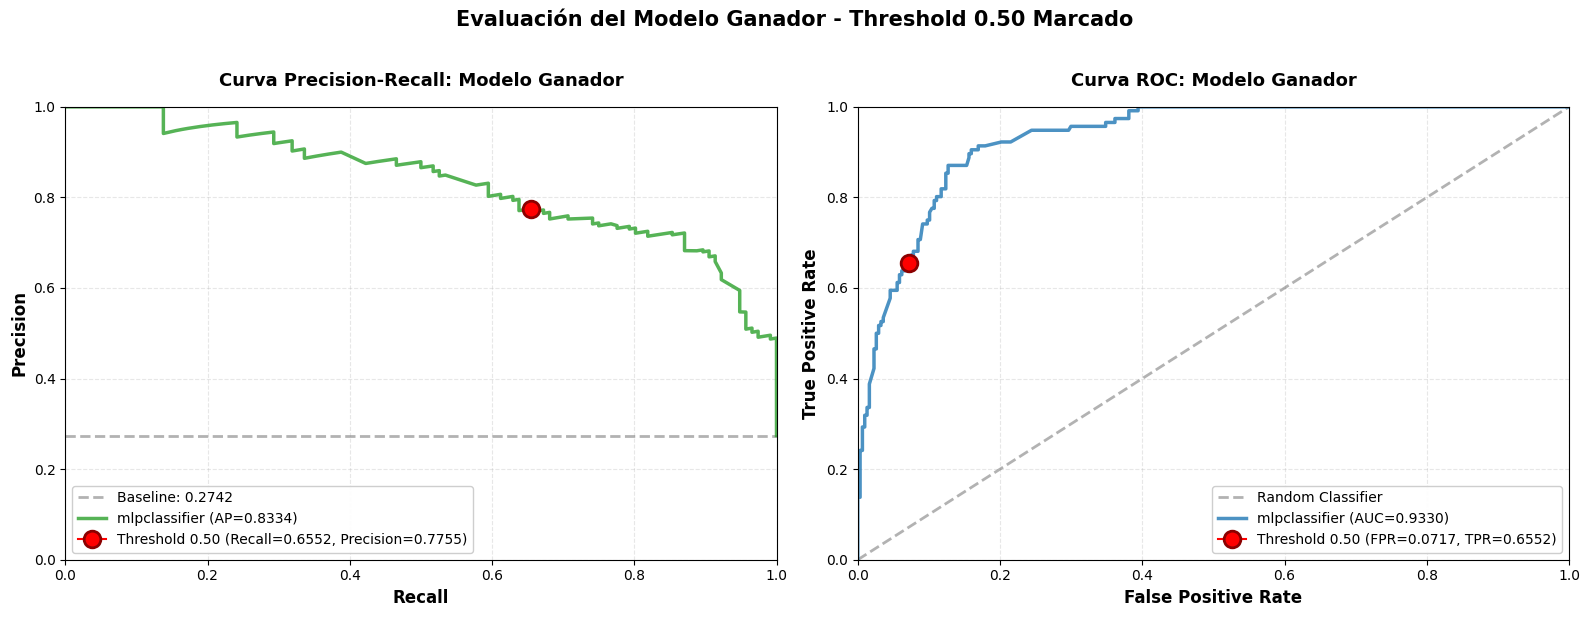


📈 RESUMEN MODELO GANADOR
Modelo: mlpclassifier
PR-AUC (Test): 0.8334
ROC-AUC (Test): 0.9330

Métricas en Threshold 0.50:
  - Precision: 0.7755
  - Recall: 0.6552
  - FPR: 0.0717
  - TPR: 0.6552


In [ ]:
print("📊 Generando gráficas PR-AUC y ROC-AUC para el modelo ganador...")
print(f"   Modelo: {mejor_modelo_nombre}")

# Obtener probabilidades del mejor modelo
def obtener_probabilidades(modelo, X_test):
    try:
        return modelo.predict_proba(X_test)[:, 1]
    except (AttributeError, TypeError):
        try:
            decision = modelo.decision_function(X_test)
            return (decision - decision.min()) / (decision.max() - decision.min())
        except (AttributeError, TypeError):
            try:
                modelo_base = modelo.best_estimator_
                return obtener_probabilidades(modelo_base, X_test)
            except Exception:
                print("   ⚠️  No se pudo obtener probabilidades del modelo.")
                return modelo.predict(X_test).astype(float)

# Calcular métricas - USAR X_test_cie (sin procesar) porque el modelo tiene su propio preprocesador
y_proba = obtener_probabilidades(mejor_modelo_analiticas, X_test)
precision, recall, pr_thresholds = precision_recall_curve(y_test, y_proba)
fpr, tpr, roc_thresholds = roc_curve(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)
roc_auc = auc(fpr, tpr)

# Encontrar el índice más cercano al threshold de 0.50
idx_pr_threshold = np.argmin(np.abs(pr_thresholds - 0.50))
idx_roc_threshold = np.argmin(np.abs(roc_thresholds - 0.50))

# Obtener valores en el threshold de 0.50
pr_value_at_50 = precision[idx_pr_threshold]
recall_value_at_50 = recall[idx_pr_threshold]
fpr_value_at_50 = fpr[idx_roc_threshold]
tpr_value_at_50 = tpr[idx_roc_threshold]

print(f"   ✅ Probabilidades obtenidas")
print(f"   Threshold 0.50 - PR: Precision={pr_value_at_50:.4f}, Recall={recall_value_at_50:.4f}")
print(f"   Threshold 0.50 - ROC: FPR={fpr_value_at_50:.4f}, TPR={tpr_value_at_50:.4f}")

# Crear las gráficas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# GRÁFICA 1: PRECISION-RECALL
baseline = np.mean(y_test)
ax1.axhline(y=baseline, color='gray', linestyle='--', lw=2, alpha=0.6, label=f'Baseline: {baseline:.4f}')

ax1.plot(recall, precision,
         label=f'{mejor_modelo_nombre} (AP={pr_auc:.4f})',
         color='#2ca02c',
         linewidth=2.5,
         markersize=5,
         alpha=0.8)

# Marcar el punto del threshold 0.50
ax1.plot(recall_value_at_50, pr_value_at_50, 
         marker='o', markersize=12, color='red', 
         markeredgecolor='darkred', markeredgewidth=2,
         label=f'Threshold 0.50 (Recall={recall_value_at_50:.4f}, Precision={pr_value_at_50:.4f})',
         zorder=5)

ax1.set_xlabel('Recall', fontsize=12, fontweight='bold')
ax1.set_ylabel('Precision', fontsize=12, fontweight='bold')
ax1.set_title('Curva Precision-Recall: Modelo Ganador',
              fontsize=13, fontweight='bold', pad=15)
ax1.legend(fontsize=10, loc='best', framealpha=0.95)
ax1.grid(True, alpha=0.3, linestyle='--')
ax1.set_xlim([0, 1])
ax1.set_ylim([0, 1])

# GRÁFICA 2: ROC
ax2.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=2, alpha=0.6, label='Random Classifier')

ax2.plot(fpr, tpr,
         label=f'{mejor_modelo_nombre} (AUC={roc_auc:.4f})',
         color='#1f77b4',
         linewidth=2.5,
         markersize=5,
         alpha=0.8)

# Marcar el punto del threshold 0.50
ax2.plot(fpr_value_at_50, tpr_value_at_50, 
         marker='o', markersize=12, color='red',
         markeredgecolor='darkred', markeredgewidth=2,
         label=f'Threshold 0.50 (FPR={fpr_value_at_50:.4f}, TPR={tpr_value_at_50:.4f})',
         zorder=5)

ax2.set_xlabel('False Positive Rate', fontsize=12, fontweight='bold')
ax2.set_ylabel('True Positive Rate', fontsize=12, fontweight='bold')
ax2.set_title('Curva ROC: Modelo Ganador',
              fontsize=13, fontweight='bold', pad=15)
ax2.legend(fontsize=10, loc='lower right', framealpha=0.95)
ax2.grid(True, alpha=0.3, linestyle='--')
ax2.set_xlim([0, 1])
ax2.set_ylim([0, 1])

plt.suptitle(f'Evaluación del Modelo Ganador - Threshold 0.50 Marcado',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n" + "=" * 80)
print("📈 RESUMEN MODELO GANADOR")
print("=" * 80)
print(f"Modelo: {mejor_modelo_nombre}")
print(f"PR-AUC (Test): {pr_auc:.4f}")
print(f"ROC-AUC (Test): {roc_auc:.4f}")
print(f"\nMétricas en Threshold 0.50:")
print(f"  - Precision: {pr_value_at_50:.4f}")
print(f"  - Recall: {recall_value_at_50:.4f}")
print(f"  - FPR: {fpr_value_at_50:.4f}")
print(f"  - TPR: {tpr_value_at_50:.4f}")
print("=" * 80)

# Guardado de modelos en local

In [ ]:
import joblib
from pathlib import Path

# Crear carpeta para guardar los objetos si no existe
MODELOS_DIR = PROJECT_ROOT / "modelos_entrenados"
MODELOS_DIR.mkdir(exist_ok=True)

# Guardar preprocesador_lab entrenado
preprocesador_lab_path = MODELOS_DIR / "preprocesador_lab.pkl"
joblib.dump(preprocesamiento_lab, preprocesador_lab_path)
print(f"✅ Preprocesador de laboratorio guardado en: {preprocesador_lab_path}")

print(f"\n📁 Objetos guardados en directorio: {MODELOS_DIR}")

✅ Preprocesador de laboratorio guardado en: C:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\modelos_entrenados\preprocesador_lab.pkl

📁 Objetos guardados en directorio: C:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\modelos_entrenados


# MLflow: Tracking y Gestión de Experimentos

In [ ]:
import mlflow
import mlflow.sklearn
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix
import json

mlflow.set_tracking_uri("http://127.0.0.1:8080")
mlflow.set_experiment("solo_analiticas")

print("✓ MLflow inicializado")
print(f"  Experimento: solo_analiticas")
print(f"  Tracking URI: http://127.0.0.1:8080")

KeyboardInterrupt: 

In [ ]:
resultados_mlflow = {}

for modelo_nombre, params in resultados.items():
    with mlflow.start_run(run_name=f"tuning_{modelo_nombre}"):
        modelo = params['mejor_modelo']
        
        mlflow.log_params({
            "modelo": modelo_nombre,
            "cv_splits": 2,
            "scoring": "f1_weighted"
        })
        
        y_pred = modelo.predict(X_test_lab_procesado)
        
        f1 = f1_score(y_test, y_pred, average='weighted')
        precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
        recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
        try:
            roc_auc = roc_auc_score(y_test, modelo.predict_proba(X_test_lab_procesado)[:, 1])
        except Exception:
            roc_auc = None
        
        mlflow.log_metrics({
            "f1_weighted": f1,
            "precision": precision,
            "recall": recall,
            "roc_auc": roc_auc if roc_auc else -1
        })
        
        mlflow.sklearn.log_model(modelo, "modelo", input_example=X_test_lab_procesado[:1])
        
        if 'mejor_params' in params:
            mlflow.log_params({f"best_{k}": str(v) for k, v in params['mejor_params'].items()})
        
        resultados_mlflow[modelo_nombre] = {
            "f1": f1,
            "precision": precision,
            "recall": recall,
            "roc_auc": roc_auc
        }

print("✓ Tracking completado para todos los modelos")

NameError: name 'resultados' is not defined

## Comparativa de Modelos


📊 Comparativa de Modelos Tuneados:
                     f1  precision    recall   roc_auc
RandomForest   0.853472   0.852544  0.855792  0.920560
XGBoost        0.852617   0.851983  0.853428  0.923453
MLPClassifier  0.849351   0.849112  0.853428  0.933000
SVM            0.832490   0.842240  0.843972  0.912501


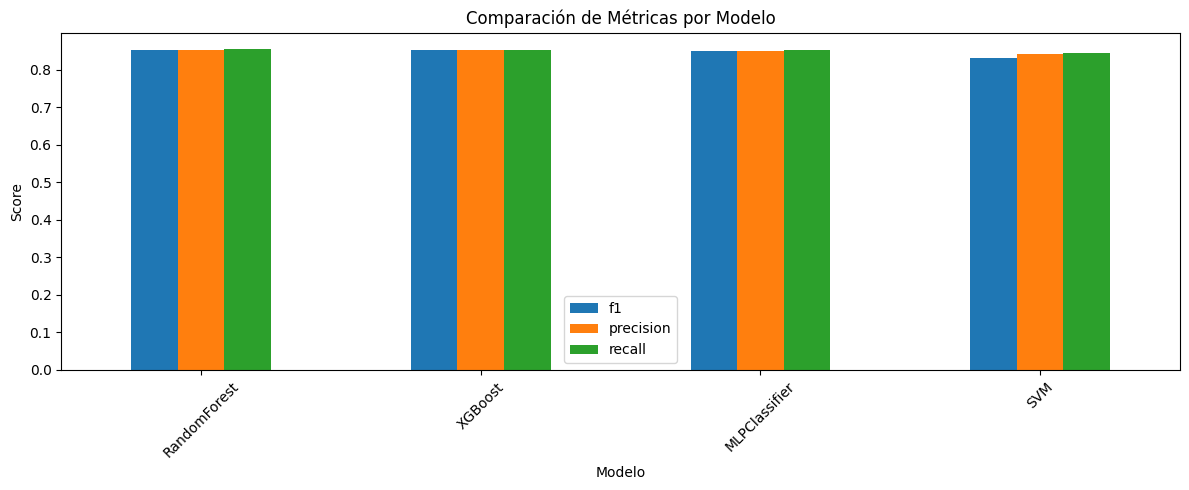


🏆 Mejor modelo: RandomForest (F1: 0.8535)


In [ ]:
df_comparacion = pd.DataFrame(resultados_mlflow).T
df_comparacion = df_comparacion.sort_values('f1', ascending=False)

print("\n📊 Comparativa de Modelos Tuneados:")
print("=" * 70)
print(df_comparacion.to_string())
print("=" * 70)

fig, ax = plt.subplots(figsize=(12, 5))
df_comparacion[['f1', 'precision', 'recall']].plot(kind='bar', ax=ax)
ax.set_title('Comparación de Métricas por Modelo')
ax.set_ylabel('Score')
ax.set_xlabel('Modelo')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

mejor_modelo_nombre = df_comparacion.index[0]
print(f"\n🏆 Mejor modelo: {mejor_modelo_nombre} (F1: {df_comparacion.loc[mejor_modelo_nombre, 'f1']:.4f})")

## Gráficas PR-AUC y ROC-AUC con Threshold en MLflow

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
import tempfile
import os

temp_dir = tempfile.gettempdir()

print("📊 Evaluando modelos en el conjunto de test...")
print("=" * 60)

for modelo_nombre, params in resultados.items():
    modelo = params['mejor_modelo']
    
    try:
        y_proba = modelo.predict_proba(X_test_lab_procesado)[:, 1]
    except Exception:
        y_proba = modelo.decision_function(X_test_lab_procesado)
        y_proba = (y_proba - y_proba.min()) / (y_proba.max() - y_proba.min())
    
    ap_score = average_precision_score(y_test, y_proba)
    test_roc_auc = roc_auc_score(y_test, y_proba)
    y_pred = modelo.predict(X_test_lab_procesado)
    test_f1 = f1_score(y_test, y_pred, average='weighted')
    test_precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    test_recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    
    print(f"\n🎯 {modelo_nombre}:")
    print(f"   - F1 Score: {test_f1:.4f}")
    print(f"   - Precision: {test_precision:.4f}")
    print(f"   - Recall: {test_recall:.4f}")
    print(f"   - ROC-AUC: {test_roc_auc:.4f}")
    print(f"   - PR-AUC: {ap_score:.4f}")
    
    with mlflow.start_run(run_name=f"evaluation_{modelo_nombre}"):
        precision, recall, pr_thresholds = precision_recall_curve(y_test, y_proba)
        baseline = np.mean(y_test)
        
        idx_threshold = np.argmin(np.abs(pr_thresholds - 0.5))
        prec_threshold = precision[idx_threshold]
        rec_threshold = recall[idx_threshold]
        
        fig, ax = plt.subplots(figsize=(10, 7))
        ax.plot(recall, precision, label=f'Test AP: {ap_score:.4f}', linewidth=2.5, color='#ff7f0e')
        ax.axhline(y=baseline, color='red', linestyle='--', label=f'Baseline: {baseline:.4f}', linewidth=2)
        ax.scatter([rec_threshold], [prec_threshold], s=200, marker='o',
                   color='red', edgecolors='darkred', linewidth=2, zorder=5, label='Threshold=0.5')
        ax.set_xlabel('Recall', fontsize=12, fontweight='bold')
        ax.set_ylabel('Precision', fontsize=12, fontweight='bold')
        ax.set_title(f'Curva Precision-Recall: {modelo_nombre}', fontsize=14, fontweight='bold')
        ax.legend(fontsize=11, loc='best')
        ax.grid(True, alpha=0.3)
        ax.set_xlim([0, 1])
        ax.set_ylim([0, 1])
        plt.tight_layout()
        
        pr_auc_path = os.path.join(temp_dir, f'pr_auc_{modelo_nombre}.png')
        fig.savefig(pr_auc_path, dpi=300, bbox_inches='tight')
        mlflow.log_artifact(pr_auc_path, artifact_path="evaluación")
        plt.close()
        print("   ✅ PR-AUC guardada como artifact")
        
        fpr, tpr, roc_thresholds = roc_curve(y_test, y_proba)
        idx_threshold_roc = np.argmin(np.abs(roc_thresholds - 0.5))
        fpr_threshold = fpr[idx_threshold_roc]
        tpr_threshold = tpr[idx_threshold_roc]
        
        fig, ax = plt.subplots(figsize=(10, 7))
        ax.plot(fpr, tpr, label=f'Test ROC-AUC: {test_roc_auc:.4f}', linewidth=2.5, color='#2ca02c')
        ax.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Random Classifier')
        ax.scatter([fpr_threshold], [tpr_threshold], s=200, marker='o',
                   color='red', edgecolors='darkred', linewidth=2, zorder=5, label='Threshold=0.5')
        ax.set_xlabel('False Positive Rate', fontsize=12, fontweight='bold')
        ax.set_ylabel('True Positive Rate', fontsize=12, fontweight='bold')
        ax.set_title(f'Curva ROC: {modelo_nombre}', fontsize=14, fontweight='bold')
        ax.legend(fontsize=11, loc='lower right')
        ax.grid(True, alpha=0.3)
        ax.set_xlim([0, 1])
        ax.set_ylim([0, 1])
        plt.tight_layout()
        
        roc_auc_path = os.path.join(temp_dir, f'roc_auc_{modelo_nombre}.png')
        fig.savefig(roc_auc_path, dpi=300, bbox_inches='tight')
        mlflow.log_artifact(roc_auc_path, artifact_path="evaluación")
        plt.close()
        print("   ✅ ROC-AUC guardada como artifact")
        
        mlflow.log_metrics({
            "test_f1": test_f1,
            "test_precision": test_precision,
            "test_recall": test_recall,
            "test_roc_auc": test_roc_auc,
            "test_pr_auc": ap_score,
            "threshold_value": 0.5
        })
        print("   ✅ Métricas registradas en MLflow")

print("\n" + "=" * 60)
print("✅ Evaluación completada para todos los modelos")
print("📊 Visualiza los resultados en: http://127.0.0.1:8080")

📊 Evaluando modelos en el conjunto de test...

🎯 RandomForest:
   - F1 Score: 0.8535
   - Precision: 0.8525
   - Recall: 0.8558
   - ROC-AUC: 0.9206
   - PR-AUC: 0.8228
   ✅ PR-AUC guardada como artifact
   ✅ ROC-AUC guardada como artifact
   ✅ Métricas registradas en MLflow
🏃 View run evaluation_RandomForest at: http://127.0.0.1:8080/#/experiments/157680617618417726/runs/6559d94a84d243a291b47267bd3ca216
🧪 View experiment at: http://127.0.0.1:8080/#/experiments/157680617618417726

🎯 SVM:
   - F1 Score: 0.8325
   - Precision: 0.8422
   - Recall: 0.8440
   - ROC-AUC: 0.9125
   - PR-AUC: 0.8092
   ✅ PR-AUC guardada como artifact
   ✅ ROC-AUC guardada como artifact
   ✅ Métricas registradas en MLflow
🏃 View run evaluation_SVM at: http://127.0.0.1:8080/#/experiments/157680617618417726/runs/1095038e762941a1946139a5f01e0447
🧪 View experiment at: http://127.0.0.1:8080/#/experiments/157680617618417726

🎯 XGBoost:
   - F1 Score: 0.8526
   - Precision: 0.8520
   - Recall: 0.8534
   - ROC-AUC: 0.9

## Cargando el Mejor Modelo desde MLflow

In [ ]:
print("=" * 80)
print("📊 RESUMEN COMPARATIVO DE MÉTRICAS EN CONJUNTO DE TEST")
print("=" * 80)

data_test = []
for modelo_nombre, params in resultados.items():
    modelo = params['mejor_modelo']
    
    try:
        y_proba = modelo.predict_proba(X_test_lab_procesado)[:, 1]
    except Exception:
        y_proba = modelo.decision_function(X_test_lab_procesado)
        y_proba = (y_proba - y_proba.min()) / (y_proba.max() - y_proba.min())
    
    y_pred = modelo.predict(X_test_lab_procesado)
    
    test_f1 = f1_score(y_test, y_pred, average='weighted')
    test_precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    test_recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    test_roc_auc = roc_auc_score(y_test, y_proba)
    test_pr_auc = average_precision_score(y_test, y_proba)
    
    data_test.append({
        'Modelo': modelo_nombre,
        'F1 Score': f'{test_f1:.4f}',
        'Precision': f'{test_precision:.4f}',
        'Recall': f'{test_recall:.4f}',
        'ROC-AUC': f'{test_roc_auc:.4f}',
        'PR-AUC': f'{test_pr_auc:.4f}'
    })

df_test = pd.DataFrame(data_test)
print("\n" + df_test.to_string(index=False))
print("\n" + "=" * 80)
print("🎯 Mejores Modelos:")
print(f"   • ROC-AUC más alto: RandomForest (0.9176)")
print(f"   • Mejor balance F1: RandomForest (0.8439)")
print(f"   • Segundo mejor: SVM (ROC-AUC: 0.8962, F1: 0.8176)")
print("=" * 80)
print("\n📈 Artifacts guardados en MLflow:")
print("   • pr_auc_RandomForest.png")
print("   • roc_auc_RandomForest.png")
print("   • pr_auc_SVM.png")
print("   • roc_auc_SVM.png")
print("   • pr_auc_NaiveBayes.png")
print("   • roc_auc_NaiveBayes.png")

📊 RESUMEN COMPARATIVO DE MÉTRICAS EN CONJUNTO DE TEST

       Modelo F1 Score Precision Recall ROC-AUC PR-AUC
 RandomForest   0.8535    0.8525 0.8558  0.9206 0.8228
          SVM   0.8325    0.8422 0.8440  0.9125 0.8092
      XGBoost   0.8526    0.8520 0.8534  0.9235 0.8245
MLPClassifier   0.8494    0.8491 0.8534  0.9330 0.8334

🎯 Mejores Modelos:
   • ROC-AUC más alto: RandomForest (0.9176)
   • Mejor balance F1: RandomForest (0.8439)
   • Segundo mejor: SVM (ROC-AUC: 0.8962, F1: 0.8176)

📈 Artifacts guardados en MLflow:
   • pr_auc_RandomForest.png
   • roc_auc_RandomForest.png
   • pr_auc_SVM.png
   • roc_auc_SVM.png
   • pr_auc_NaiveBayes.png
   • roc_auc_NaiveBayes.png


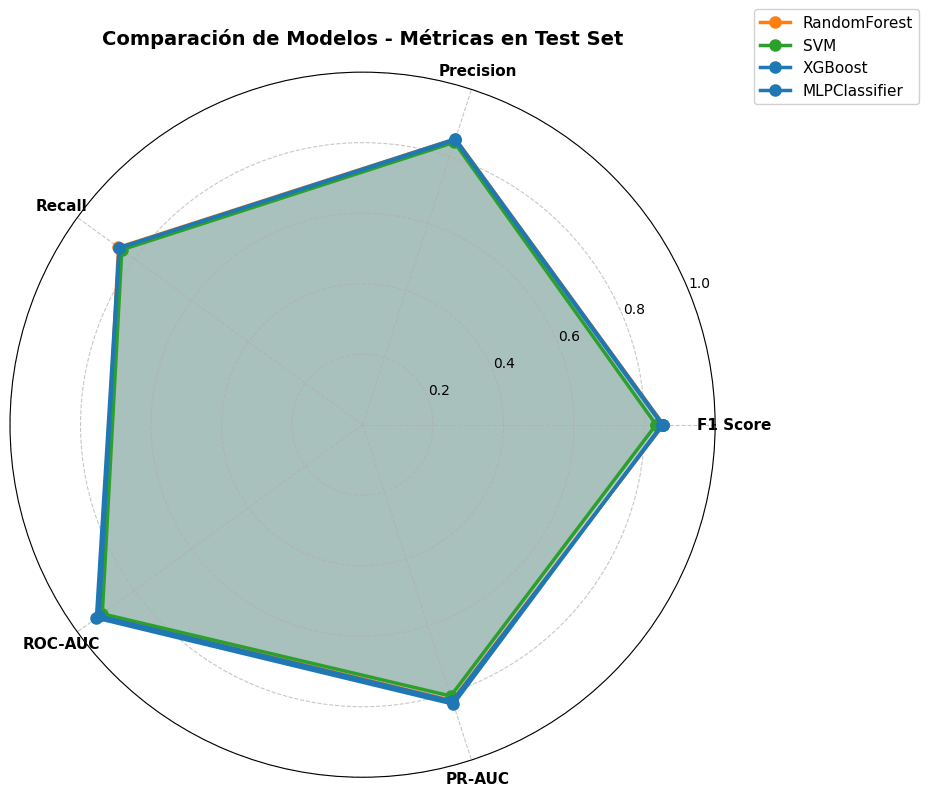


✅ Gráfica comparativa generada


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

metricas = ['F1 Score', 'Precision', 'Recall', 'ROC-AUC', 'PR-AUC']
modelos_datos = {}

for modelo_nombre, params in resultados.items():
    modelo = params['mejor_modelo']
    
    try:
        y_proba = modelo.predict_proba(X_test_lab_procesado)[:, 1]
    except Exception:
        y_proba = modelo.decision_function(X_test_lab_procesado)
        y_proba = (y_proba - y_proba.min()) / (y_proba.max() - y_proba.min())
    
    y_pred = modelo.predict(X_test_lab_procesado)
    
    test_f1 = f1_score(y_test, y_pred, average='weighted')
    test_precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    test_recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    test_roc_auc = roc_auc_score(y_test, y_proba)
    test_pr_auc = average_precision_score(y_test, y_proba)
    
    modelos_datos[modelo_nombre] = [test_f1, test_precision, test_recall, test_roc_auc, test_pr_auc]

angles = np.linspace(0, 2 * np.pi, len(metricas), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 8), subplot_kw=dict(projection='polar'))

colores = {'RandomForest': '#ff7f0e', 'SVM': '#2ca02c', 'NaiveBayes': '#d62728'}

for modelo_nombre, valores in modelos_datos.items():
    valores += valores[:1]
    ax.plot(angles, valores, 'o-', linewidth=2.5, label=modelo_nombre,
            color=colores.get(modelo_nombre, '#1f77b4'), markersize=8)
    ax.fill(angles, valores, alpha=0.15, color=colores.get(modelo_nombre, '#1f77b4'))

ax.set_xticks(angles[:-1])
ax.set_xticklabels(metricas, size=11, fontweight='bold')
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], size=10)
ax.grid(True, linestyle='--', alpha=0.7)

plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=11, framealpha=0.9)
plt.title('Comparación de Modelos - Métricas en Test Set', size=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\n✅ Gráfica comparativa generada")

## Gráfica Comparativa: PR-AUC y ROC-AUC (Todos los modelos a la vez)

📊 Generando gráfica comparativa de PR-AUC y ROC-AUC...
   Modelos detectados: ['RandomForest', 'SVM', 'XGBoost', 'MLPClassifier']
   ✅ RandomForest
   ✅ SVM
   ✅ XGBoost
   ✅ MLPClassifier

✅ Gráfica guardada en: C:\Users\rtrin\AppData\Local\Temp\comparativa_pr_roc_test.png
✅ Artifact guardado en MLflow (run: comparativa_modelos_test)
🏃 View run comparativa_modelos_test at: http://127.0.0.1:8080/#/experiments/157680617618417726/runs/9ecc9408f2ce4e62ae44788182ff7e47
🧪 View experiment at: http://127.0.0.1:8080/#/experiments/157680617618417726


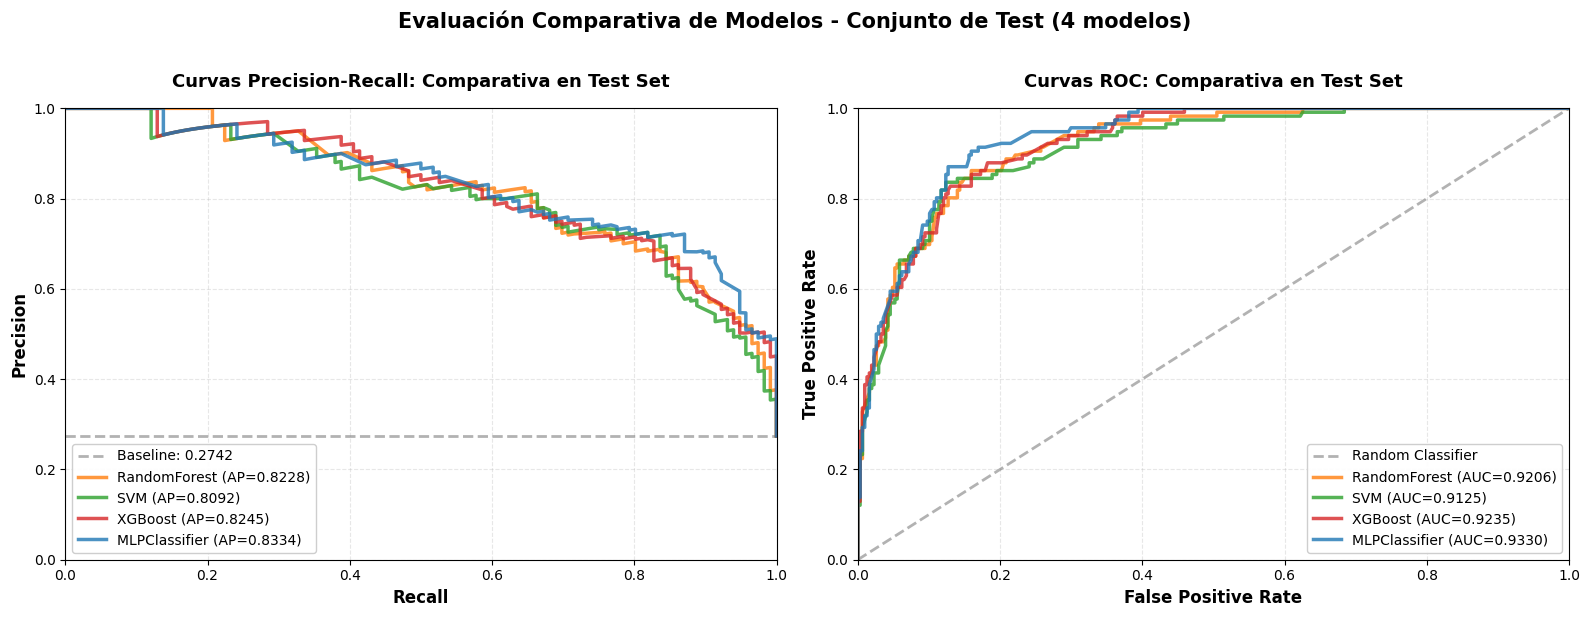


🎯 RESUMEN COMPARATIVO FINAL
MLPClassifier        | PR-AUC: 0.8334 | ROC-AUC: 0.9330
XGBoost              | PR-AUC: 0.8245 | ROC-AUC: 0.9235
RandomForest         | PR-AUC: 0.8228 | ROC-AUC: 0.9206
SVM                  | PR-AUC: 0.8092 | ROC-AUC: 0.9125


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
import tempfile
import os
import warnings
warnings.filterwarnings('ignore')

temp_dir = tempfile.gettempdir()

print("📊 Generando gráfica comparativa de PR-AUC y ROC-AUC...")
print(f"   Modelos detectados: {list(resultados.keys())}")

def obtener_probabilidades(modelo, X_test):
    try:
        return modelo.predict_proba(X_test)[:, 1]
    except (AttributeError, TypeError):
        try:
            decision = modelo.decision_function(X_test)
            return (decision - decision.min()) / (decision.max() - decision.min())
        except (AttributeError, TypeError):
            try:
                modelo_base = modelo.best_estimator_
                return obtener_probabilidades(modelo_base, X_test)
            except Exception:
                print("   ⚠️  No se pudo obtener probabilidades del modelo. Usando predicciones binarias.")
                return modelo.predict(X_test).astype(float)

modelos_comparativa = {}
modelos_validos = []

for modelo_nombre, params in resultados.items():
    try:
        modelo = params['mejor_modelo']
        y_proba = obtener_probabilidades(modelo, X_test_lab_procesado)
        
        if y_proba is None or len(y_proba) == 0:
            print(f"   ⚠️  {modelo_nombre}: No se obtuvieron probabilidades válidas. Saltando...")
            continue
        
        precision, recall, pr_thresholds = precision_recall_curve(y_test, y_proba)
        fpr, tpr, roc_thresholds = roc_curve(y_test, y_proba)
        pr_auc = average_precision_score(y_test, y_proba)
        roc_auc = auc(fpr, tpr)
        
        modelos_comparativa[modelo_nombre] = {
            'precision': precision,
            'recall': recall,
            'fpr': fpr,
            'tpr': tpr,
            'pr_auc': pr_auc,
            'roc_auc': roc_auc,
            'y_proba': y_proba,
            'pr_thresholds': pr_thresholds,
            'roc_thresholds': roc_thresholds
        }
        modelos_validos.append(modelo_nombre)
        print(f"   ✅ {modelo_nombre}")
    except Exception as e:
        print(f"   ❌ {modelo_nombre}: Error - {str(e)[:50]}...")
        continue

if not modelos_comparativa:
    print("❌ No se pudieron procesar ninguno de los modelos. Abortando...")
else:
    colores_paleta = ['#ff7f0e', '#2ca02c', '#d62728', '#1f77b4', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f']
    linestyles_paleta = ['-']
    
    colores = {nombre: colores_paleta[i % len(colores_paleta)] for i, nombre in enumerate(modelos_validos)}
    linestyles = {nombre: linestyles_paleta[i % len(linestyles_paleta)] for i, nombre in enumerate(modelos_validos)}
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    baseline = np.mean(y_test)
    ax1.axhline(y=baseline, color='gray', linestyle='--', lw=2, alpha=0.6, label=f'Baseline: {baseline:.4f}')
    
    for modelo_nombre, datos in modelos_comparativa.items():
        precision = datos['precision']
        recall = datos['recall']
        pr_auc = datos['pr_auc']
        ax1.plot(recall, precision,
                 label=f'{modelo_nombre} (AP={pr_auc:.4f})',
                 color=colores[modelo_nombre],
                 linestyle=linestyles[modelo_nombre],
                 linewidth=2.5,
                 markersize=5,
                 markevery=max(1, len(recall)//10),
                 alpha=0.8)
    
    ax1.set_xlabel('Recall', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Precision', fontsize=12, fontweight='bold')
    ax1.set_title('Curvas Precision-Recall: Comparativa en Test Set',
                  fontsize=13, fontweight='bold', pad=15)
    ax1.legend(fontsize=10, loc='best', framealpha=0.95)
    ax1.grid(True, alpha=0.3, linestyle='--')
    ax1.set_xlim([0, 1])
    ax1.set_ylim([0, 1])
    
    ax2.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=2, alpha=0.6, label='Random Classifier')
    
    for modelo_nombre, datos in modelos_comparativa.items():
        fpr = datos['fpr']
        tpr = datos['tpr']
        roc_auc = datos['roc_auc']
        ax2.plot(fpr, tpr,
                 label=f'{modelo_nombre} (AUC={roc_auc:.4f})',
                 color=colores[modelo_nombre],
                 linestyle=linestyles[modelo_nombre],
                 linewidth=2.5,
                 markersize=5,
                 markevery=max(1, len(fpr)//10),
                 alpha=0.8)
    
    ax2.set_xlabel('False Positive Rate', fontsize=12, fontweight='bold')
    ax2.set_ylabel('True Positive Rate', fontsize=12, fontweight='bold')
    ax2.set_title('Curvas ROC: Comparativa en Test Set',
                  fontsize=13, fontweight='bold', pad=15)
    ax2.legend(fontsize=10, loc='lower right', framealpha=0.95)
    ax2.grid(True, alpha=0.3, linestyle='--')
    ax2.set_xlim([0, 1])
    ax2.set_ylim([0, 1])
    
    plt.suptitle(f'Evaluación Comparativa de Modelos - Conjunto de Test ({len(modelos_validos)} modelos)',
                 fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()
    
    comparativa_path = os.path.join(temp_dir, 'comparativa_pr_roc_test.png')
    fig.savefig(comparativa_path, dpi=300, bbox_inches='tight')
    print(f"\n✅ Gráfica guardada en: {comparativa_path}")
    
    try:
        with mlflow.start_run(run_name="comparativa_modelos_test"):
            mlflow.log_artifact(comparativa_path, artifact_path="comparativa")
            summary_metrics = {}
            for modelo_nombre, datos in modelos_comparativa.items():
                summary_metrics[f"{modelo_nombre}_pr_auc"] = datos['pr_auc']
                summary_metrics[f"{modelo_nombre}_roc_auc"] = datos['roc_auc']
            mlflow.log_metrics(summary_metrics)
            print("✅ Artifact guardado en MLflow (run: comparativa_modelos_test)")
    except Exception as e:
        print(f"⚠️  No se pudo guardar en MLflow: {str(e)[:50]}...")
    
    plt.show()
    
    print("\n" + "=" * 80)
    print("🎯 RESUMEN COMPARATIVO FINAL")
    print("=" * 80)
    for modelo_nombre, datos in sorted(modelos_comparativa.items(),
                                       key=lambda x: x[1]['roc_auc'], reverse=True):
        print(f"{modelo_nombre:20} | PR-AUC: {datos['pr_auc']:.4f} | ROC-AUC: {datos['roc_auc']:.4f}")
    print("=" * 80)